# Part 3: text EDA of the modelling classes (era B)

Continues `newsspace_analysis.ipynb` and repeats the text analysis of the first EDA (`old_eda.ipynb`) on the
new data. Input: `newsspace_era_b.csv` from `python prepare_newsspace.py newsSpace.bz2 --full`.

Only the five modelling classes are used, and the text analysis (3.3–3.7) looks at the **training split only**, so
nothing learned here comes from validation or test. As in `--train`, each article is kept once (title compared
ignoring case and spacing) and titles with more than one label are dropped.

In [1]:
import re
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from bs4 import MarkupResemblesLocatorWarning, XMLParsedAsHTMLWarning
from IPython.display import display
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.manifold import TSNE
from sklearn.metrics import pairwise_distances
from wordcloud import STOPWORDS, WordCloud

# the notebook lives in eda/; the data, dictionaries/ and preprocess.py are in the project root
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
sys.path.insert(0, str(ROOT))
from preprocess import HtmlCleaner

strip_html = HtmlCleaner().transform   # P1: unescape HTML entities, drop the tags

warnings.filterwarnings('ignore', category=MarkupResemblesLocatorWarning)
warnings.filterwarnings('ignore', category=XMLParsedAsHTMLWarning)
pd.set_option('display.width', 180)
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.grid': True, 'grid.alpha': 0.3})

CLASSES = ['World', 'Sports', 'Business', 'Sci/Tech', 'Entertainment']
SPLITS = ['train', 'val', 'test', 'test-future']
FIELDS = ['title', 'description', 'all']

df = pd.read_csv(ROOT / 'newsspace_era_b.csv', dtype=str, keep_default_na=False)
df = df[df['category'].isin(CLASSES)].copy()
df['title_key'] = df['title'].str.split().str.join(' ').str.lower()
n_five = len(df)
df = df[df.groupby('title_key')['category'].transform('nunique') == 1].drop_duplicates('title_key')
print(f'{n_five:,} rows of the five classes -> {len(df):,} clean articles')

371,337 rows of the five classes -> 271,961 clean articles


## 3.1 Classes per split

clean articles per split (the pool that prepare_newsspace.py --train samples from):


split,train,val,test,test-future,train %,val %,test %,test-future %
category,,,,,,,,
World,39968,8662,8589,11137,25.2,25.2,25.0,25.1
Sports,21388,4721,4706,7083,13.5,13.7,13.7,16.0
Business,31340,6874,6747,9516,19.7,20.0,19.6,21.4
Sci/Tech,47022,10102,10242,9869,29.6,29.4,29.8,22.2
Entertainment,19092,4048,4094,6761,12.0,11.8,11.9,15.2


articles in splits/*.csv, the files that B0, B1 and the P variants use:


,train,val,test,test-future
World,19092,4331,4294,5568
Sports,19092,2360,2353,3541
Business,19092,3437,3373,4758
Sci/Tech,19092,5051,5121,4934
Entertainment,19092,2024,2047,3380
total,95460,17203,17188,22181


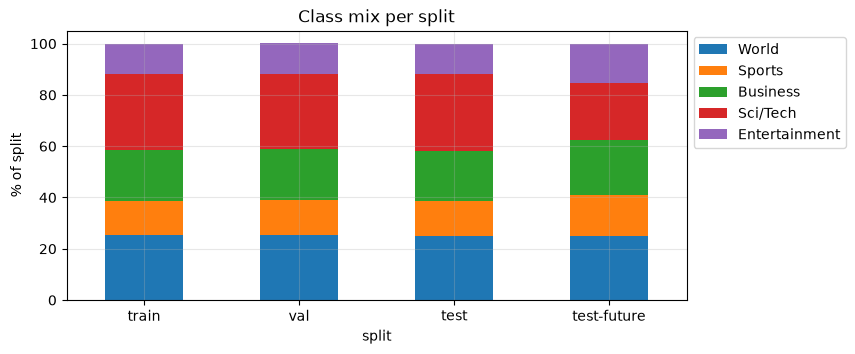

In [2]:
counts = pd.crosstab(df['category'], df['split']).loc[CLASSES, SPLITS]
shares = counts.div(counts.sum()).mul(100).round(1)
print('clean articles per split (the pool that prepare_newsspace.py --train samples from):')
display(pd.concat([counts, shares.add_suffix(' %')], axis=1))
used = pd.DataFrame({s: pd.read_csv(ROOT / 'splits' / f'{s}.csv', usecols=['category'])['category'].value_counts()
                     for s in SPLITS}).loc[CLASSES]
print('articles in splits/*.csv, the files that B0, B1 and the P variants use:')
display(pd.concat([used, used.sum().to_frame('total').T]))
shares.T.plot.bar(stacked=True, figsize=(8, 3.5), rot=0, ylabel='% of split', title='Class mix per split')
plt.legend(bbox_to_anchor=(1, 1))
plt.show()

* train / val / test have the same class mix (split by title hash). Classes are not balanced (Sci/Tech 30%,
  Entertainment 12%), so macro-F1 is the right main metric.
* **test-future** has a different mix: Sci/Tech drops to 22%, Sports and Entertainment rise to 15-16%.
* The first table is the clean pool; the models use the second one. `--train` samples the training split down to
  19,092 articles per class (the size of Entertainment, under the 20,000 limit) and keeps half of each class in val,
  test and test-future, so those keep their natural mix. The text analysis below uses the whole clean training split
  (first table), which contains `train.csv`.

## 3.2 Missing values and duplicates between splits

In [3]:
desc_key = df['description'].str.split().str.join(' ').str.lower()
has_desc = desc_key.ne('')
dup_desc = desc_key[has_desc].groupby(desc_key).transform('size') > 1
cross = df[has_desc].assign(k=desc_key).groupby('k')['split'].nunique()
print(f"empty description: {(~has_desc).mean():.2%}   empty title: {df['title'].str.strip().eq('').mean():.2%}")
print(f"titles in more than one split: {df.groupby('title_key')['split'].nunique().gt(1).sum()} (split by title hash)")
print(f"descriptions repeated under another title: {dup_desc.mean():.2%} of rows; "
      f"{cross.gt(1).sum():,} such descriptions occur in 2+ splits")

# near duplicates: same title after removing everything but letters
loose = df['title_key'].str.replace(r'[^a-z]', '', regex=True)
print(f"titles equal after dropping digits/punctuation, but in different splits: "
      f"{df.groupby(loose)['split'].nunique().gt(1).sum():,}")
display(df[has_desc & desc_key.isin(cross[cross.gt(1)].index)]
        .assign(k=desc_key).sort_values('k')[['split', 'category', 'title', 'description']].head(6))

empty description: 3.26%   empty title: 0.00%


titles in more than one split: 0 (split by title hash)
descriptions repeated under another title: 4.86% of rows; 1,795 such descriptions occur in 2+ splits


titles equal after dropping digits/punctuation, but in different splits: 547


,split,category,title,description
336866,train,Business,H&R Block net income rises 9 percent,"(Reuters) - H&R Block Inc. , the largest U.S. ..."
336815,val,Business,H&R Block Q4 net income from cont ops rises 9 ...,"(Reuters) - H&R Block Inc. , the largest U.S. ..."
498175,val,Sci/Tech,CSC announces another round of job cuts,<h4>Government unit targeted</h4>\n<p>CSC is s...
498629,train,Sci/Tech,CSC announces another round of UK job cuts,<h4>Government unit targeted</h4>\n<p>CSC is s...
475763,val,Entertainment,Midcentury Moderns in a Cross-Cultural Convers...,A bamboo chair provides a departure point for ...
473811,train,Entertainment,Design Review | 'Design: Isamu Noguchi and Isa...,A bamboo chair provides a departure point for ...


* No title is in two splits, and only 3.3% of descriptions are empty.
* Leaks remain through **near duplicates**: 547 titles differ only in digits/punctuation, and 1,795 descriptions occur
  in two splits under a different title (updated versions of the same story, as above). That is <1% of the rows, but
  worth removing from val/test before the final comparison.

## 3.3 Text length (train)

From here on the text is the training split with HTML removed from title and description (`preprocess.HtmlCleaner`, the P1 step); *all* is title + description.

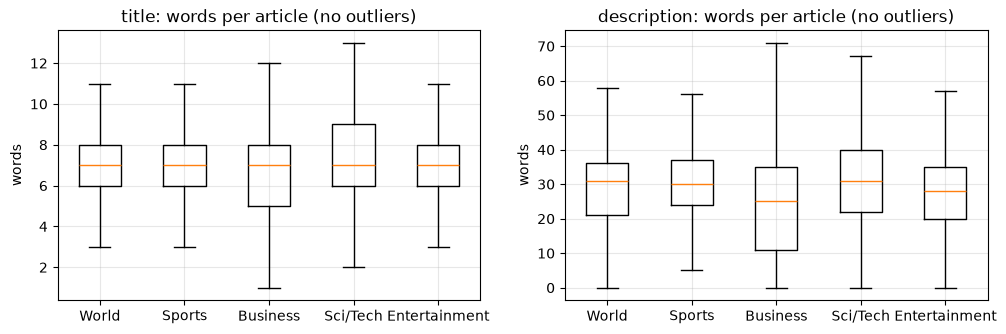

,median words in title,median words in description
category,,
World,7.0,31.0
Sports,7.0,30.0
Business,7.0,25.0
Sci/Tech,7.0,31.0
Entertainment,7.0,28.0


In [4]:
tr = df[df['split'].eq('train')].reset_index(drop=True)
for f in ['title', 'description']:
    tr[f] = strip_html(tr[f].tolist())
tr['all'] = tr['title'] + ' ' + tr['description']

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, f in zip(axes, ['title', 'description']):
    words = tr[f].str.split().str.len()
    ax.boxplot([words[tr['category'].eq(c)] for c in CLASSES], tick_labels=CLASSES, showfliers=False)
    ax.set(title=f'{f}: words per article (no outliers)', ylabel='words')
plt.show()
tr.groupby('category')[['title', 'description']].agg(lambda s: s.str.split().str.len().median()).loc[CLASSES] \
  .rename(columns=lambda c: f'median words in {c}')

* Titles are short (median 7 words) in every class; descriptions about 4x longer.
* **Business** has the most short or empty descriptions (lower quartile ~11 words), so it should profit most from
  adding the title.

## 3.4 Word clouds (train, stop words removed)

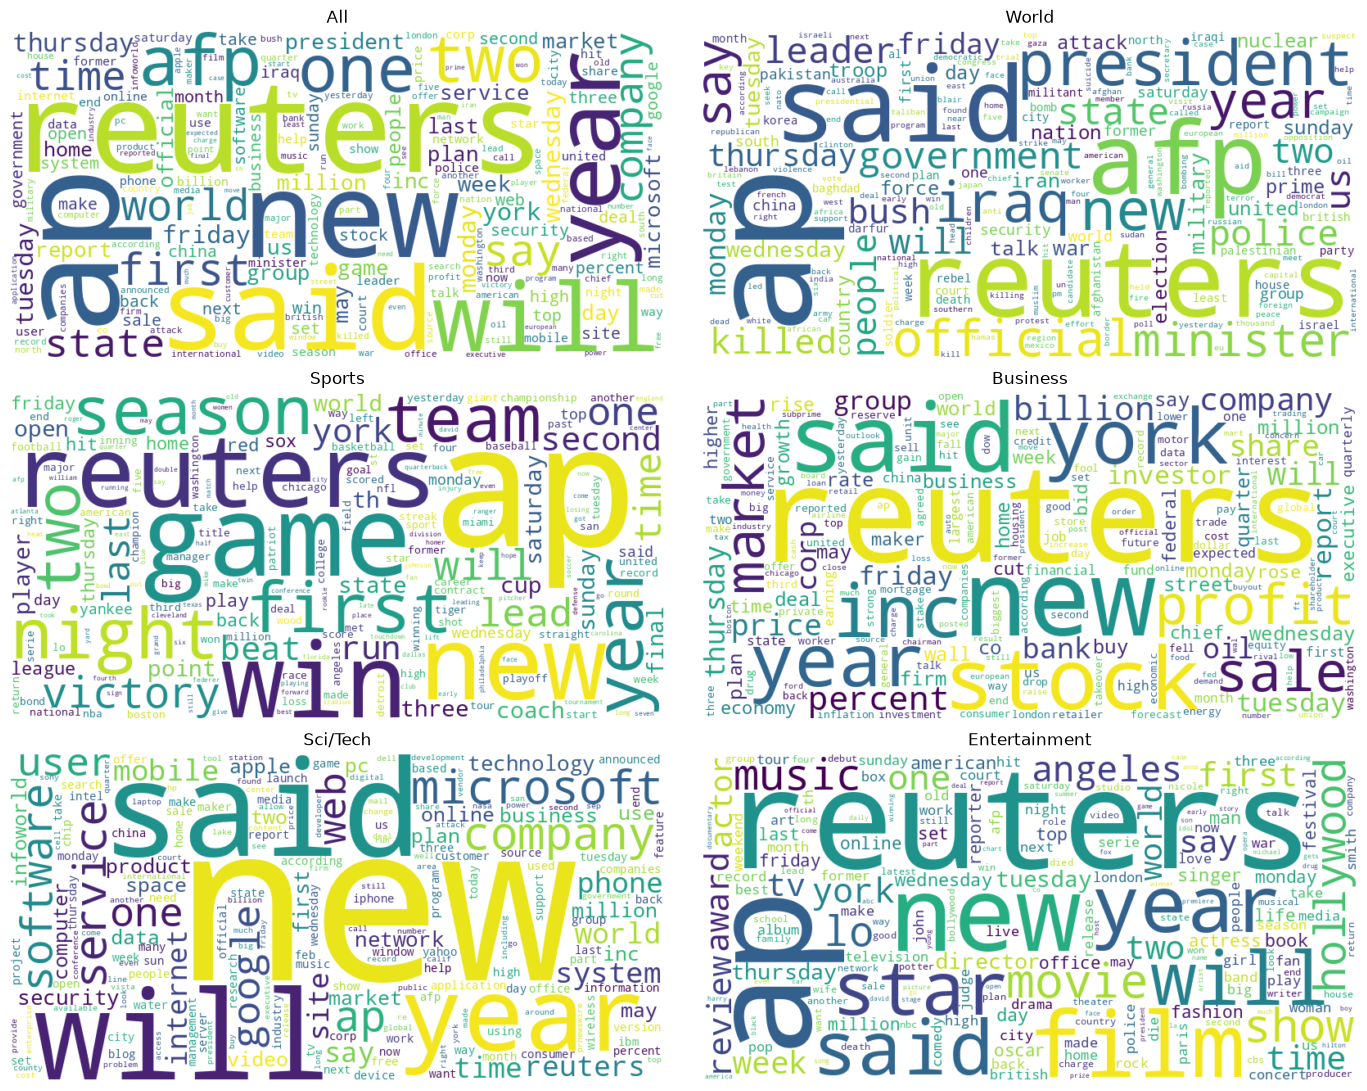

In [5]:
def clean_text(texts):
    words = ' '.join(texts).lower()
    words = re.sub(r'[^a-z\s]', ' ', words).split()
    return ' '.join(w for w in words if w not in STOPWORDS and len(w) > 1)


text = {(c, f): clean_text(tr.loc[tr['category'].eq(c), f]) for c in CLASSES for f in FIELDS}
for f in FIELDS:
    text['All', f] = ' '.join(text[c, f] for c in CLASSES)

fig, axes = plt.subplots(3, 2, figsize=(14, 11))
for ax, c in zip(axes.flat, ['All'] + CLASSES):
    ax.imshow(WordCloud(width=800, height=400, background_color='white', collocations=False, random_state=0)
              .generate(text[c, 'all']), interpolation='bilinear')
    ax.set_title(c)
    ax.axis('off')
fig.tight_layout()
plt.show()

* The largest words in every class are agency names and weekdays (*ap*, *reuters*, *afp*, *said*,
  *new*, *year*, weekdays): they say who wrote the article and when, not what it is about.
* HTML entities such as `&quot;` occur in titles as well as descriptions (3.7); both fields are cleaned here, so
  no entity remnants (*quot*, *amp*) are left among the words.
* Without those, the topics are clear: *iraq, minister, president* / *team, game, season* / *market, stock,
  company* / *microsoft, google, software* / *film, movie, star*.

## 3.5 Most characteristic words per class

The old EDA listed the most frequent words, which are similar in every class. Here, words are ranked by how much more
often they occur in the class than in the rest: a smoothed log ratio of the two frequencies (words with ≥ 50
occurrences).

In [6]:
def top_words(field, k=12):
    cv = CountVectorizer(min_df=1)
    X = cv.fit_transform([text[c, field] for c in CLASSES]).toarray().astype(float)
    vocab = cv.get_feature_names_out()
    keep = X.sum(0) >= 50
    out = {}
    for i, c in enumerate(CLASSES):
        rest = X.sum(0) - X[i]
        ratio = np.log((X[i] + 1) / (X[i].sum())) - np.log((rest + 1) / rest.sum())
        ratio[~keep] = -np.inf
        out[c] = vocab[np.argsort(-ratio)[:k]]
    return pd.DataFrame(out)


for f in ['title', 'description']:
    print(f)
    display(top_words(f))

title


,World,Sports,Business,Sci/Tech,Entertainment
0,cqpolitics,padres,blackstone,infoworld,playbill
1,taliban,sabres,recession,server,jolie
2,olmert,homers,uaw,techweb,rapper
3,timor,phillies,bernanke,newsfactor,lohan
4,hamas,knicks,countrywide,firefox,actor
5,bombing,bengals,jobless,macworld,nicole
6,militants,orioles,subprime,voip,bollywood
7,shiite,broncos,hedge,virtualization,venice
8,lede,celtics,foolish,patches,spector
9,abbas,astros,alcan,linux,anna


description


,World,Sports,Business,Sci/Tech,Entertainment
0,ehud,quarterfinals,bernanke,prnewswire,playbill
1,olmert,shutout,blackstone,infoworld,kapoor
2,fatah,baseman,alcan,firstcall,jolie
3,cqpolitics,bruins,cos,jun,angelina
4,timor,phillies,chrysler,voip,bachchan
5,iraqis,bullpen,mortgages,malware,amitabh
6,hamas,homered,futures,server,rapper
7,disarmament,outfielder,hedge,sep,spector
8,leftist,panthers,subprime,gsm,bollywood
9,ite,linebacker,drugmaker,mozilla,crowe


* The characteristic words are mostly **proper names** (*olmert, hamas, phillies, jolie, firefox*) and
  **source names** (*cqpolitics, infoworld, techweb, macworld, prnewswire, playbill*; *foolish/fools* = The Motley
  Fool). The source almost fixes the class, so a model can learn the source instead of the topic.

## 3.6 Class separability

Each class is one document (all its training text), compared by cosine distance, as in the old EDA, in two
representations and three fields. Darker means more similar. (Binary BoW is left out: on five huge documents almost
every word is present everywhere, so all distances come out ~0.5.)

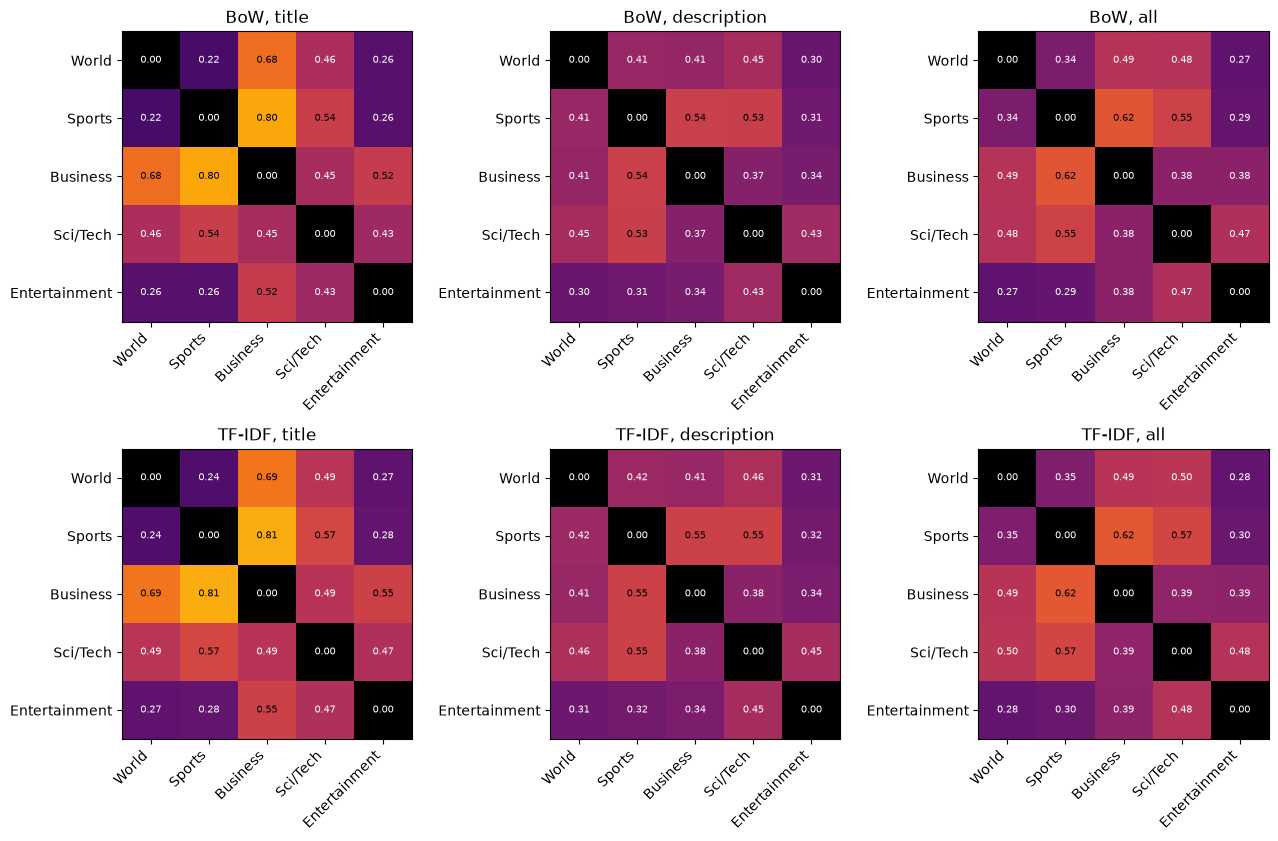

In [7]:
def distance_plot(field, vectorizer, ax):
    X = vectorizer.fit_transform([text[c, field] for c in CLASSES])
    d = pairwise_distances(X, metric='cosine')
    ax.imshow(d, vmin=0, vmax=1, cmap='inferno')
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            ax.text(j, i, f'{d[i, j]:.2f}', ha='center', va='center', fontsize=7,
                    color='white' if d[i, j] < 0.5 else 'black')
    ax.set_xticks(range(len(CLASSES)), CLASSES, rotation=45, ha='right')
    ax.set_yticks(range(len(CLASSES)), CLASSES)
    ax.grid(False)


reps = {'BoW': CountVectorizer(), 'TF-IDF': TfidfVectorizer()}
fig, axes = plt.subplots(2, 3, figsize=(13, 8.5))
for row, (name, vec) in zip(axes, reps.items()):
    for ax, f in zip(row, FIELDS):
        distance_plot(f, vec, ax)
        ax.set_title(f'{name}, {f}')
fig.tight_layout()
plt.show()

With only five class documents, TF-IDF's IDF is nearly flat (most words occur in every class), so the matrices
above show mostly *overlap of vocabularies*. A view per article: t-SNE of 500 training articles per class, TF-IDF
fitted on the training split, reduced to 50 dimensions with SVD.

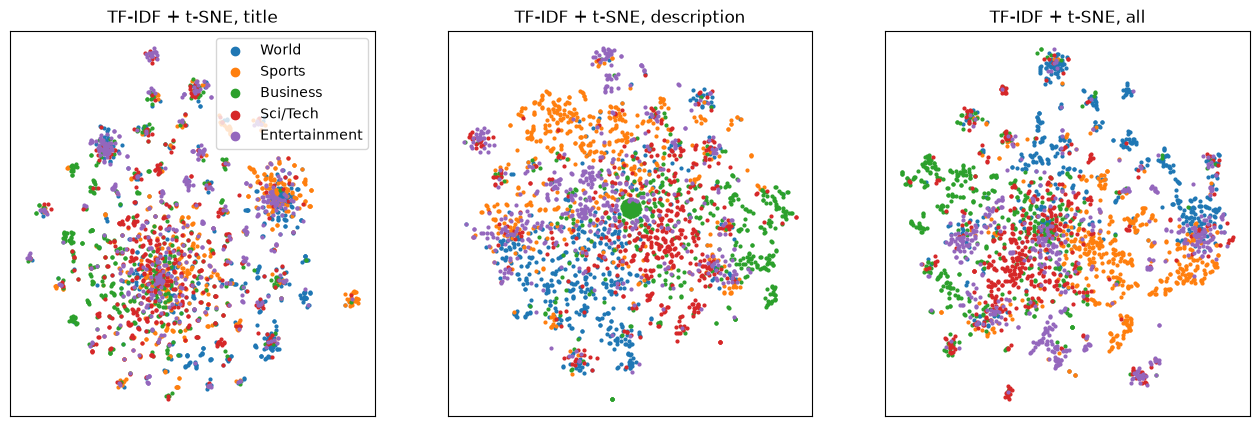

In [8]:
small = tr.groupby('category').sample(500, random_state=42)
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, f in zip(axes, FIELDS):
    tfidf = TfidfVectorizer(stop_words='english', min_df=2).fit(tr[f])
    Z = TruncatedSVD(50, random_state=42).fit_transform(tfidf.transform(small[f]))
    E = TSNE(2, random_state=42, init='pca').fit_transform(Z)
    for c in CLASSES:
        m = small['category'].eq(c).to_numpy()
        ax.scatter(E[m, 0], E[m, 1], s=4, label=c)
    ax.set(title=f'TF-IDF + t-SNE, {f}', xticks=[], yticks=[])
axes[0].legend(markerscale=3)
plt.show()

* **Sports** and **Business** are the most separable classes (largest distances). World, Sports and Entertainment
  are close in BoW, mostly because they share the agency words *ap*/*reuters*; TF-IDF barely changes that here.
* Titles alone separate worst: in t-SNE most title points form one mixed cloud with small clusters of repeated
  headlines. Description and title + description give visible class regions, with World/Business/Sci/Tech overlapping
  in the middle (also the pairs that share titles most, see 2.2).

## 3.7 Artifacts

Formatting left in the **raw** text (before P1), per class, and the most frequent tokens that are not in the
English word list that P3 uses (`dictionaries/sowpods.txt`, see `models/p3b1.json`).

In [9]:
raw = df[df['split'].eq('train')].set_index(tr.index)
raw_all = raw['title'] + ' ' + raw['description']
TAG = r'(?i)</?(?:a|p|br|img|font|b|i|u|div|span|table|tr|td|ul|ol|li|strong|em|h[1-6]|hr|blockquote|nobr)\b[^>]*>'
flags = pd.DataFrame({
    'HTML tag': raw_all.str.contains(TAG),
    'HTML entity': raw_all.str.contains(r'&(?:#\d+|[a-zA-Z]+);'),
    'entity left after P1': tr['all'].str.contains(r'&(?:#\d+|[a-zA-Z]+);'),
    'URL': raw_all.str.contains(r'https?://|www\.'),
    'digit': tr['all'].str.contains(r'\d'),
    'non-ASCII': tr['all'].str.contains(r'[^\x00-\x7f]'),
})
display(flags.groupby(tr['category']).mean().mul(100).round(1).loc[CLASSES].rename(columns=lambda c: c + ' %'))

with open(ROOT / 'dictionaries' / 'sowpods.txt') as f:
    dictionary = {w.strip().lower() for w in f}
tokens = pd.Series(' '.join(text[c, 'all'] for c in CLASSES).split())
oov = tokens[~tokens.isin(dictionary)]
print(f'tokens outside the word list: {len(oov) / len(tokens):.1%} of all (letters-only) tokens')
oov.value_counts().head(30).to_frame('count').T

,HTML tag %,HTML entity %,entity left after P1 %,URL %,digit %,non-ASCII %
category,,,,,,
World,39.4,10.4,0.0,39.4,30.4,6.0
Sports,34.4,6.2,0.0,34.4,56.0,9.6
Business,24.7,3.8,0.0,24.7,35.2,6.1
Sci/Tech,36.1,5.6,0.0,29.0,46.8,16.4
Entertainment,33.0,11.7,0.0,29.3,28.8,12.8


tokens outside the word list: 18.1% of all (letters-only) tokens


,ap,reuters,afp,thursday,tuesday,wednesday,friday,monday,inc,microsoft,...,british,th,iran,pc,european,angeles,ibm,feb,india,iphone
count,51510,41362,13227,9615,9227,8990,8768,8702,7400,7167,...,3251,2966,2881,2869,2825,2655,2572,2535,2412,2287


## 3.8 Summary and hypotheses for P1–P3

| | finding | hypothesis |
|---|---|---|
| **P1** HTML / entity normalisation | 25-39% of rows have HTML tags (mostly links), 4-12% HTML entities, in titles as well as descriptions | small gain, mainly less noise |
| **P2** stop words | titles have ~7 words; stop words carry no class information, and TF-IDF already down-weights them | roughly neutral, possibly a small loss on titles |
| **P3** dictionary filter | 18% of tokens are outside the word list, and they include the most characteristic ones (names, sources) | clear **loss** |
| number normalisation | digits in 29-56% of rows, most in Sports (scores) and Sci/Tech (versions, prices) | small effect; may help Sports |
| **P5** fields | titles are short and separate worst; descriptions are often empty in Business | title + description > description > title |

Other points for the experiments: source and agency tokens are shortcuts (removing *ap/reuters/afp/...* is a
possible extra experiment); test-future has a different class mix; <1% near-duplicate leaks between splits (3.2).